In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
DATA_DIR = Path("../data")
MONTHS = ["2026-07", "2026-08", "2026-09"]

In [6]:
from pathlib import Path
import pandas as pd

# Find all Parquet files inside the data folder
project_dir = Path("..")
data_dir = project_dir / "data"

files = sorted(data_dir.rglob("*.parquet"))

print(f"Found {len(files)} Parquet files:")
for file in files:
    print(file)

Found 3 Parquet files:
..\data\data-2026-07.parquet
..\data\data-2026-08.parquet
..\data\data-2026-09.parquet


In [7]:
# Load the first file so we can inspect its structure
df = pd.read_parquet(files[0])

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Rows and columns: (14768104, 23)

Column names:
['station_name', 'xml_station_name', 'eva', 'train_number', 'line_number', 'final_destination_station', 'delay_in_min', 'time', 'arrival_is_canceled', 'departure_is_canceled', 'train_type', 'is_additional_stop', 'is_replacement_train', 'replaced_train_type', 'replaced_train_number', 'has_plan_record', 'train_line_ride_id', 'train_line_station_num', 'arrival_planned_time', 'arrival_change_time', 'departure_planned_time', 'departure_change_time', 'id']


,station_name,xml_station_name,eva,train_number,line_number,final_destination_station,delay_in_min,time,arrival_is_canceled,departure_is_canceled,...,replaced_train_type,replaced_train_number,has_plan_record,train_line_ride_id,train_line_station_num,arrival_planned_time,arrival_change_time,departure_planned_time,departure_change_time,id
0,Meckesheim,Meckesheim,08003932,38781,S7,Sinsheim(Elsenz) Hbf,1.0,2026-07-01,False,False,...,NaN,NaN,True,1684730927053936465,10,2026-06-30 23:59:00,2026-06-30 23:59:00,2026-06-30 23:59:00,2026-07-01,1684730927053936465-2606302335-10
1,Berlin Westkreuz,Berlin Westkreuz,08089047,42243,S42,Berlin Südkreuz (S),3.0,2026-07-01,False,False,...,NaN,NaN,True,4125414136633665630,21,2026-06-30 23:57:00,2026-06-30 23:59:00,2026-06-30 23:57:00,2026-07-01,4125414136633665630-2606302309-21
2,Stuttgart Feuersee,Stuttgart Feuersee,08006699,7277,S2,Filderstadt,1.0,2026-07-01,False,False,...,NaN,NaN,True,-1263112065111090114,17,2026-06-30 23:58:00,2026-07-01 00:00:00,2026-06-30 23:59:00,2026-07-01,-1263112065111090114-2606302318-17
3,Bretten-Ruit,Bretten-Ruit,08001131,19658,RB71,Bruchsal,1.0,2026-07-01,False,False,...,NaN,NaN,True,568059394542159172,6,2026-06-30 23:59:00,2026-06-30 23:59:00,2026-06-30 23:59:00,2026-07-01,568059394542159172-2606302345-6
4,Hattersheim (Main),Hattersheim(Main),08002637,35183,S1,Rödermark-Ober Roden,1.0,2026-07-01,False,False,...,NaN,NaN,True,-551609556134806098,7,2026-06-30 23:58:00,2026-06-30 23:59:00,2026-06-30 23:59:00,2026-07-01,-551609556134806098-2606302335-7


In [8]:
# 1. Understand the size of the dataset
print("Dataset size:", df.shape)

# 2. Inspect column names and data types
df.info()

# 3. Check how many values are missing in each column
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

# 4. Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Look at basic statistics
df.describe(include="all").T

Dataset size: (14768104, 23)
<class 'pandas.DataFrame'>
RangeIndex: 14768104 entries, 0 to 14768103
Data columns (total 23 columns):
 #   Column                     Dtype         
---  ------                     -----         
 0   station_name               str           
 1   xml_station_name           str           
 2   eva                        str           
 3   train_number               str           
 4   line_number                str           
 5   final_destination_station  str           
 6   delay_in_min               float64       
 7   time                       datetime64[ns]
 8   arrival_is_canceled        bool          
 9   departure_is_canceled      bool          
 10  train_type                 str           
 11  is_additional_stop         bool          
 12  is_replacement_train       bool          
 13  replaced_train_type        str           
 14  replaced_train_number      str           
 15  has_plan_record            bool          
 16  train_line_ride_

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
station_name,14763170,5296,München Hbf,64602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xml_station_name,14768104,5341,Berlin Ostkreuz (S),49541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eva,14768104,5342,08089028,49541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
train_number,14276283,62405,3148,1642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
line_number,14480331,388,S1,1455289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
final_destination_station,14247400,2448,Berlin Beusselstraße,287481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delay_in_min,14276283.0,NaN,NaN,NaN,3.458125,-1441.0,0.0,1.0,3.0,1380.0,8.420893
time,14768104,NaN,NaN,NaN,2026-07-16 10:56:58.305000704,2026-07-01 00:00:00,2026-07-08 14:57:00,2026-07-16 08:43:00,2026-07-24 08:05:00,2026-07-31 23:59:00,NaN
arrival_is_canceled,14768104,2,False,14194316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_is_canceled,14768104,2,False,14194772,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Count missing delay values
print("Missing delay values:", df["delay_in_min"].isna().sum())

# Understand the distribution of delay values
print(df["delay_in_min"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

# Check the proportion of canceled arrivals and departures
print("\nArrival cancellations:")
print(df["arrival_is_canceled"].value_counts(dropna=False))

print("\nDeparture cancellations:")
print(df["departure_is_canceled"].value_counts(dropna=False))

# Inspect the delay values recorded most frequently
print("\nMost frequent delay values:")
print(df["delay_in_min"].value_counts(dropna=False).head(15))

Missing delay values: 491821
count    1.427628e+07
mean     3.458125e+00
std      8.420893e+00
min     -1.441000e+03
25%      0.000000e+00
50%      1.000000e+00
75%      3.000000e+00
90%      9.000000e+00
95%      1.500000e+01
99%      3.800000e+01
max      1.380000e+03
Name: delay_in_min, dtype: float64

Arrival cancellations:
arrival_is_canceled
False    14194316
True       573788
Name: count, dtype: int64

Departure cancellations:
departure_is_canceled
False    14194772
True       573332
Name: count, dtype: int64

Most frequent delay values:
delay_in_min
0.0     5262465
1.0     3176164
2.0     1438916
3.0      893945
4.0      635380
NaN      491821
5.0      478874
6.0      363783
7.0      281542
8.0      222814
9.0      178831
10.0     148288
11.0     120553
12.0     101398
13.0      85969
Name: count, dtype: int64


In [10]:
# Examine arrival cancellations and missing delays together
print(pd.crosstab(
    df["arrival_is_canceled"],
    df["delay_in_min"].isna(),
    margins=True
))

delay_in_min            False    True       All
arrival_is_canceled                            
False                13706426  487890  14194316
True                   569857    3931    573788
All                  14276283  491821  14768104


In [11]:
# Inspect the most extreme negative delays
print(
    df.nsmallest(10, "delay_in_min")[
        ["station_name", "train_type", "time",
         "delay_in_min", "arrival_is_canceled"]
    ]
)


                               station_name train_type                time  \
11561610                          Rosenheim         NJ 2026-07-25 08:45:00   
14321376                     Regensburg Hbf         RE 2026-07-31 06:12:00   
11939368                        München Hbf         NJ 2026-07-26 06:46:00   
10793912           Lübeck-Travemünde Strand         RE 2026-07-23 15:34:00   
10795134            Lübeck-Travemünde Hafen         RE 2026-07-23 15:37:00   
10796664  Lübeck-Travemünde Skandinavienkai         RE 2026-07-23 15:40:00   
10798662                    Lübeck-Kücknitz         RE 2026-07-23 15:44:00   
10800621            Lübeck-Dänischburg IKEA         RE 2026-07-23 15:49:00   
5219429                          Greifswald        PRE 2026-07-11 16:54:00   
5614354                          Greifswald        PRE 2026-07-12 16:54:00   

          delay_in_min  arrival_is_canceled  
11561610       -1441.0                False  
14321376        -172.0                False  
119

In [12]:
# Inspect the most extreme positive delays
print(
    df.nlargest(10, "delay_in_min")[
        ["station_name", "train_type", "time",
         "delay_in_min", "arrival_is_canceled"]
    ]
)

                            station_name train_type                time  \
13619554                        Köln Hbf        EUR 2026-07-29 17:05:00   
13645108                      Aachen Hbf        EUR 2026-07-29 18:00:00   
12783028      Hannover-Linden/Fischerhof        SBH 2026-07-27 23:42:00   
10713727                  Bad König-Zell        Bus 2026-07-23 12:28:00   
10716557                     Michelstadt        Bus 2026-07-23 12:35:00   
10719189             Erbach (Odenw) Nord        Bus 2026-07-23 12:41:00   
10720149                  Erbach (Odenw)        Bus 2026-07-23 12:43:00   
4810006            Neufahrn (b Freising)        Bus 2026-07-10 18:37:00   
4817171   Flughafen München Besucherpark        Bus 2026-07-10 18:52:00   
4819814                Flughafen München        Bus 2026-07-10 18:57:00   

          delay_in_min  arrival_is_canceled  
13619554        1380.0                False  
13645108        1380.0                False  
12783028        1367.0              

In [13]:
#Established that the highest delays (Minimum or maximum) are not canceled, so we can filter out canceled trains and look at the distribution of delays for non-canceled trains.

In [14]:
DELAY_COLUMN = "delay_in_min"
LATE_THRESHOLD_MIN = 6  # a stop is "late" at this many minutes or more
STOP_COLUMNS = [
    "train_type", "eva", "station_name",
    DELAY_COLUMN, "arrival_is_canceled", "departure_is_canceled",
]
MIN_STOPS_PER_TYPE = 1_000     # ignore train types with fewer stops
MIN_STOPS_PER_STATION = 200    # ignore stations with fewer stops
TOP_N = 5                      # how many worst train types to follow up

In [15]:
def prepare_stops(stops: pd.DataFrame) -> pd.DataFrame:
    """Keep stops where lateness can be judged, and add an is_late flag."""
    stops = stops[STOP_COLUMNS]
    missing_delay = stops[DELAY_COLUMN].isna()
    cancelled = stops["arrival_is_canceled"] | stops["departure_is_canceled"]
    kept = stops[~missing_delay & ~cancelled].copy()

    print(f"Total stops:                 {len(stops):,}")
    print(f"Removed, no delay recorded:  {missing_delay.sum():,}")
    print(f"Removed, cancelled:          {cancelled.sum():,}")
    print(f"Kept (the rules can overlap): {len(kept):,}")

    kept["is_late"] = kept[DELAY_COLUMN] >= LATE_THRESHOLD_MIN
    return kept


def late_summary(stops: pd.DataFrame, by: str, min_stops: int) -> pd.DataFrame:
    """Count stops and late stops per group, with the late rate."""
    summary = stops.groupby(by, observed=True).agg(
        stops=("is_late", "size"),
        late_stops=("is_late", "sum"),
    )
    summary["late_rate"] = summary["late_stops"] / summary["stops"]
    enough = summary["stops"] >= min_stops
    return summary[enough].sort_values("late_rate", ascending=False)


def station_names(stops: pd.DataFrame) -> pd.Series:
    """Map each station number (eva) to one readable station name."""
    return stops.drop_duplicates(subset="eva").set_index("eva")["station_name"]

In [16]:
stops = prepare_stops(df)
overall_rate = stops["is_late"].mean()
print(f"\nOverall late rate: {overall_rate:.1%}")

Total stops:                 14,768,104
Removed, no delay recorded:  491,821
Removed, cancelled:          651,697
Kept (the rules can overlap): 13,629,267

Overall late rate: 16.1%


In [17]:
by_type = late_summary(stops, "train_type", MIN_STOPS_PER_TYPE)

print("Most OFTEN late (rate):")
display(by_type.head(10).round({"late_rate": 3}))

print("Most late stops (count):")
display(by_type.sort_values("late_stops", ascending=False).head(10).round({"late_rate": 3}))

Most OFTEN late (rate):


,stops,late_stops,late_rate
train_type,,,
NJ,4573,2961,0.647
EN,2007,1214,0.605
FLX,5390,3240,0.601
TGV,1502,828,0.551
ALX,5488,2976,0.542
ICE,172472,91343,0.530
ECE,3680,1867,0.507
RJ,6112,3088,0.505
EC,3403,1701,0.500


Most late stops (count):


,stops,late_stops,late_rate
train_type,,,
S,5932630,714671,0.120
RE,1292679,319099,0.247
RB,1691624,255460,0.151
ICE,172472,91343,0.530
NX,164174,74821,0.456
HLB,304434,63554,0.209
VIA,163119,55945,0.343
ARV,241883,53494,0.221
ERB,202558,50455,0.249


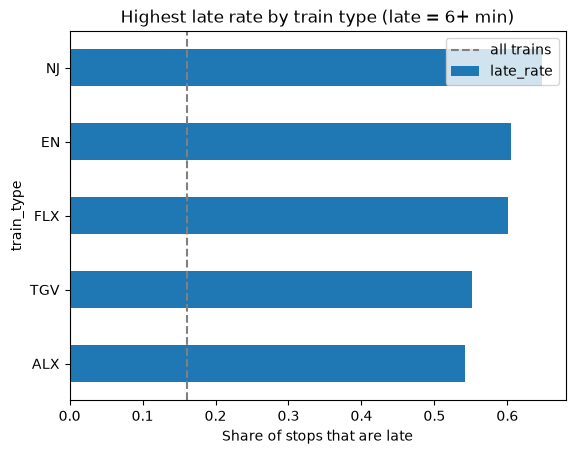

In [23]:
worst = by_type.head(TOP_N)

ax = worst["late_rate"].sort_values().plot.barh()
ax.axvline(overall_rate, color="grey", linestyle="--", label="all trains")
ax.set_xlabel("Share of stops that are late")
ax.set_title(f"Highest late rate by train type (late = {LATE_THRESHOLD_MIN}+ min)")
ax.legend()
plt.show()
ax.figure.savefig(FIGURES_DIR / "late_rate_by_train_type.png", dpi=150, bbox_inches="tight")

In [19]:
worst_type_stops = stops[stops["train_type"].isin(worst.index)]
by_station = late_summary(worst_type_stops, "eva", MIN_STOPS_PER_STATION)
by_station = by_station.join(station_names(stops))

print("Stations where these trains are late most OFTEN (rate):")
display(by_station.head(10).round({"late_rate": 3}))

print("Stations with the MOST late stops from these trains (count):")
display(by_station.sort_values("late_stops", ascending=False).head(10).round({"late_rate": 3}))

Stations where these trains are late most OFTEN (rate):


,stops,late_stops,late_rate,station_name
eva,,,,
08002041,249,194,0.779,Frankfurt (Main) Süd
08000115,242,187,0.773,Fulda
08000191,558,428,0.767,Karlsruhe Hbf
08000244,389,291,0.748,Mannheim Hbf
08010101,202,147,0.728,Erfurt Hbf
08010159,216,157,0.727,Halle (Saale) Hbf
08001330,430,311,0.723,Cham (Oberpf)
08000098,328,228,0.695,Essen Hbf
08000290,295,205,0.695,Offenburg


Stations with the MOST late stops from these trains (count):


,stops,late_stops,late_rate,station_name
eva,,,,
08000191,558,428,0.767,Karlsruhe Hbf
08000027,630,391,0.621,Schwandorf
08002078,655,382,0.583,Freising
08000309,656,376,0.573,Regensburg Hbf
08000217,655,376,0.574,Landshut (Bay) Hbf
08098160,652,374,0.574,Berlin Hauptbahnhof
08011113,651,356,0.547,Berlin Südkreuz
08000688,631,356,0.564,Neufahrn (Niederbay)
08000261,898,340,0.379,München Hbf


In [20]:
REPORTS_DIR = Path("../reports")
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

In [21]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

by_type.to_csv(TABLES_DIR / "late_rate_by_train_type.csv")
by_station.to_csv(TABLES_DIR / "late_rate_by_station_worst_types.csv")

In [24]:
def add_type_late_rate(stops: pd.DataFrame) -> pd.DataFrame:
    """Add each stop's train-type late rate, measured across all stations."""
    type_rate = stops.groupby("train_type", observed=True)["is_late"].mean()
    typed = stops.copy()
    typed["type_late_rate"] = typed["train_type"].map(type_rate).astype("float64")
    return typed


def station_vs_expected(stops: pd.DataFrame, min_stops: int) -> pd.DataFrame:
    """Per station: actual late rate vs the rate its train mix would predict."""
    stations = stops.groupby("eva", observed=True).agg(
        stops=("is_late", "size"),
        late_rate=("is_late", "mean"),
        expected_rate=("type_late_rate", "mean"),
    )
    stations["excess"] = stations["late_rate"] - stations["expected_rate"]
    return stations[stations["stops"] >= min_stops]

In [25]:
typed_stops = add_type_late_rate(stops)
stations = station_vs_expected(typed_stops, MIN_STOPS_PER_STATION).join(station_names(stops))

correlation = stations["late_rate"].corr(stations["expected_rate"])
print(f"Stations analysed: {len(stations):,}")
print(f"Correlation: {correlation:.2f}")
print(f"Train mix explains roughly {correlation**2:.0%} of the differences between stations")

Stations analysed: 5,271
Correlation: 0.54
Train mix explains roughly 29% of the differences between stations


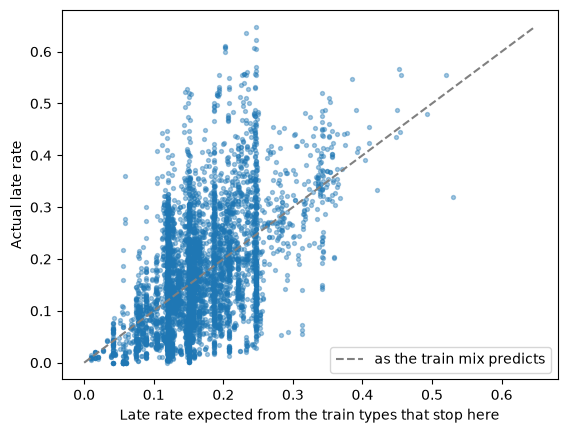

In [26]:
ax = stations.plot.scatter(x="expected_rate", y="late_rate", s=8, alpha=0.4)
top = stations[["expected_rate", "late_rate"]].max().max()
ax.plot([0, top], [0, top], color="grey", linestyle="--", label="as the train mix predicts")
ax.set_xlabel("Late rate expected from the train types that stop here")
ax.set_ylabel("Actual late rate")
ax.legend()
ax.figure.savefig(FIGURES_DIR / "station_late_rate_vs_train_mix.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
COLUMNS = ["station_name", "stops", "late_rate", "expected_rate", "excess"]

print("Worse than their train mix predicts:")
display(stations.sort_values("excess", ascending=False)[COLUMNS].head(10).round(3))

print("Better than their train mix predicts:")
display(stations.sort_values("excess")[COLUMNS].head(10).round(3))

stations.to_csv(TABLES_DIR / "station_late_rate_vs_expected.csv")

Worse than their train mix predicts:


,station_name,stops,late_rate,expected_rate,excess
eva,,,,,
08003791,Lützel,898,0.611,0.202,0.409
08006117,Vormwald,898,0.608,0.202,0.406
08002826,Hilchenbach,956,0.608,0.202,0.406
08003316,Klein Winternheim-Ober Olm,1132,0.636,0.232,0.404
08003230,Kempten (Allgäu) Ost,787,0.648,0.247,0.401
08006118,Vormwald Dorf,911,0.599,0.202,0.397
08001858,Erpel (Rhein),347,0.527,0.147,0.380
08003660,Leubsdorf (Rhein),348,0.523,0.144,0.379
08001454,Dietmannsried,1166,0.623,0.247,0.376


Better than their train mix predicts:


,station_name,stops,late_rate,expected_rate,excess
eva,,,,,
08002815,Oberzent-Hetzbach,495,0.055,0.313,-0.258
08005393,Oberzent-Schöllenbach,495,0.063,0.313,-0.250
08003144,Oberzent-Kailbach,495,0.073,0.313,-0.240
08004816,Pfungstadt,1251,0.060,0.292,-0.232
08001886,Eschweiler Hbf,2331,0.054,0.284,-0.230
08000328,Schnabelwaid,672,0.028,0.247,-0.219
08012902,Schönberg (Meckl),795,0.030,0.244,-0.214
08004909,Quierschied,1412,0.021,0.233,-0.212
08003680,Limburg Süd,823,0.320,0.530,-0.210
